In [8]:
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt

X, y =make_classification(n_samples=100, n_features=2, n_informative=1, n_redundant=0,
                        n_classes=2, n_clusters_per_class=1, random_state=41, 
                        hypercube=False, class_sep=10)

In [9]:
print('INPUT values: \n', X)

INPUT values: 
 [[ 0.19924745 -0.11697552]
 [-0.24882029 -0.73115232]
 [-0.3544904  -0.7081059 ]
 [-1.59086506 -2.01199214]
 [-0.20083951  1.63493163]
 [-0.83241122  0.15599044]
 [-1.79207014  1.07782053]
 [ 0.0856607   0.80626713]
 [-0.55865299  0.74859527]
 [-1.95974262  0.75152794]
 [-1.77828947 -0.90114581]
 [-1.77985853 -0.1815243 ]
 [-0.02194151 -2.98092432]
 [ 0.80563431  1.20500136]
 [-1.82701214  0.78302407]
 [ 0.38730728  0.42968688]
 [-0.14108668 -0.73229726]
 [-1.87955941 -0.83930476]
 [-0.18232911  0.83727062]
 [-1.77059533 -0.10255323]
 [-2.27658028  0.65867001]
 [-2.06519502  0.92649819]
 [-1.31690551  0.10216193]
 [ 1.61043259  0.46886454]
 [-1.21650394  0.45432938]
 [ 0.6139723   1.8613386 ]
 [-1.78760957 -0.79255991]
 [-1.04149161 -1.0004391 ]
 [-2.40067584 -0.53814137]
 [-1.80383452  0.44027716]
 [-1.44075613  0.27047889]
 [ 1.34989978 -0.75869267]
 [ 0.22520167  0.6802322 ]
 [ 0.53688527  0.17018845]
 [ 0.55483459 -1.01121977]
 [-0.32178185 -0.8394709 ]
 [-0.9882124

In [10]:
print('OUTPUT values: \n', y)


OUTPUT values: 
 [1 1 1 0 1 0 0 1 1 0 0 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 0 0 0 0 1 1 1 1 1 0
 1 0 1 0 0 0 1 0 1 1 0 0 0 1 1 0 1 1 0 1 0 0 1 1 0 0 1 1 1 0 1 0 0 0 1 1 0
 1 1 0 1 0 1 1 1 0 1 1 0 0 0 1 0 1 1 0 0 1 0 0 0 1 1]


In [14]:
print(X.shape)
print(y.shape)

print(X[:5])
print(y[:5])

(100, 2)
(100,)
[[ 0.19924745 -0.11697552]
 [-0.24882029 -0.73115232]
 [-0.3544904  -0.7081059 ]
 [-1.59086506 -2.01199214]
 [-0.20083951  1.63493163]]
[1 1 1 0 1]


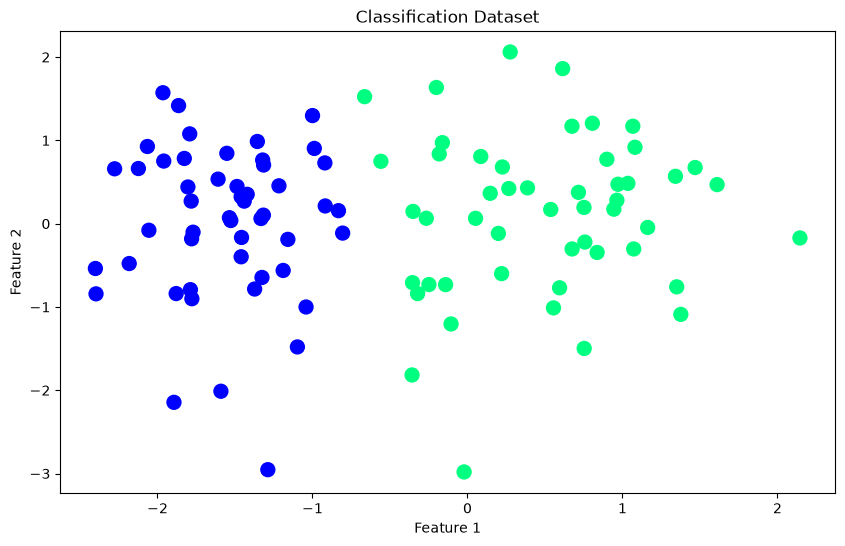

In [17]:
plt.figure(figsize=(10,6))

plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Classification Dataset')

plt.show()

In [20]:
def Perceptron(X, y):
    X = np.insert(X, 0, 1, axis=1)

    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(100):
        j = np.random.randint(0, X.shape[0])

        y_hat = step(np.dot(X[j], weights))

        weights = weights + lr * (y[j] - y_hat) * X[j]

    return weights[0], weights[1:]


def step(z):
    return 1 if z > 0 else 0

In [22]:
intercept_, coef_ = Perceptron(X,y)

print(coef_)
print(intercept_)

[1.24548391 0.08418853]
1.0


In [23]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [24]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input +b

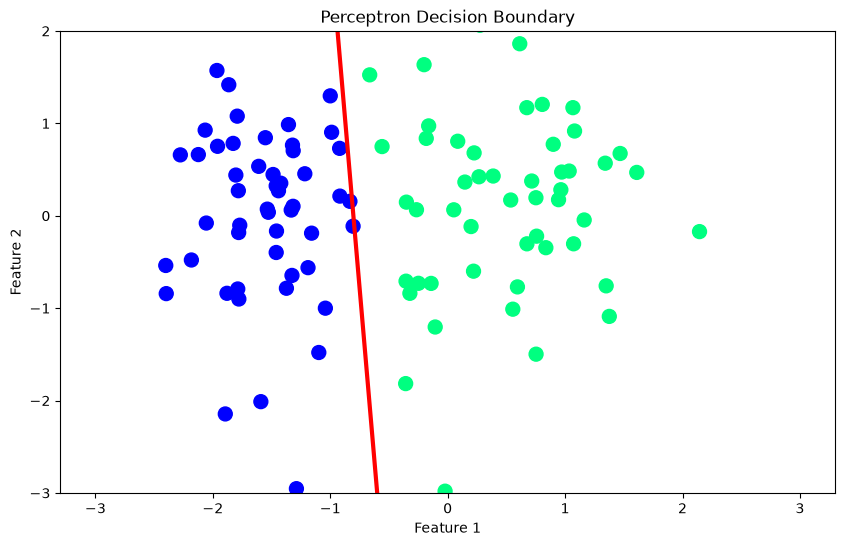

In [26]:
plt.figure(figsize=(10,6))

plt.plot(x_input, y_input, color='red', linewidth=3)

plt.scatter(X[:,0], X[:,1], c=y, cmap="winter", s=100)

plt.ylim(-3,2)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Perceptron Decision Boundary')
plt.show()

In [27]:
def Perceptron(X, y):

    m= []
    b= []



    X = np.insert(X, 0, 1, axis=1)

    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(100):
        j = np.random.randint(0, X.shape[0])

        y_hat = step(np.dot(X[j], weights))

        weights = weights + lr * (y[j] - y_hat) * X[j]

        m.append(-(weights[1]/weights[2]))
        b.append(-(weights[0]/weights[2]))

    return m,b


In [28]:
m,b = Perceptron(X,y)

In [34]:
%matplotlib inline

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(9,5))

x_i = np.arange(-3, 3, 0.1)

ax.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)

line, = ax.plot(
    x_i,
    x_i*m[0] + b[0],
    'r-',
    linewidth=2
)

ax.set_ylim(-3, 3)

def update(i):

    label = 'epoch {0}'.format(i + 1)

    line.set_ydata(x_i*m[i] + b[i])

    ax.set_xlabel(label)

    return line,

anim = FuncAnimation(
    fig,
    update,
    repeat=True,
    frames=len(m),
    interval=100
)

plt.close(fig)

HTML(anim.to_jshtml())

<IPython.core.display.Javascript object>